# 🏠 House Price Prediction — End-to-End Machine Learning Project

**Goal:** predict the sale price of a house from its physical features and amenities, and find out which features matter most.

**Workflow:** Load → Validate data → EDA → Pipeline (preprocessing + model) → Cross-validated model comparison → Hyper-parameter tuning → Final test evaluation → Residual diagnostics → Feature importance → Prediction on a new house → Insights, limitations & conclusion.

> **How to run:** run from the repository root (the dataset is read from `data/`). In Colab, upload `House_Price_Prediction_Dataset.xlsx` next to the notebook, then *Runtime → Restart and run all*.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42          # one seed => fully reproducible results
FILE = "House_Price_Prediction_Dataset.xlsx"
# works from the repo root, from notebooks/, or in Colab after uploading the file next to the notebook
DATA_PATH = next(p for p in [Path("data")/FILE, Path("../data")/FILE, Path(FILE)] if p.exists())
IMG_DIR, MODEL_DIR = Path("images"), Path("models")
IMG_DIR.mkdir(exist_ok=True); MODEL_DIR.mkdir(exist_ok=True)

def save_fig(name):
    # Save the current figure to images/ (used by the README) before it is shown
    plt.savefig(IMG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}" if abs(x) < 10 else f"{x:,.0f}")

## 2. Load the dataset

In [2]:
df = pd.read_excel(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (500, 13)


,Area_sqft,Bedrooms,Bathrooms,Stories,MainRoad,GuestRoom,Basement,HotWaterHeating,AirConditioning,Parking,PreferredArea,FurnishingStatus,Price
0,1512,1,3,2,Yes,Yes,Yes,Yes,No,0,Yes,Furnished,5780117
1,2505,5,5,1,Yes,No,Yes,No,No,0,Yes,Unfurnished,9645286
2,3387,3,2,2,No,Yes,Yes,No,Yes,2,No,Unfurnished,9651340
3,955,6,4,1,No,Yes,No,No,Yes,0,Yes,Unfurnished,6946937
4,2970,1,2,1,No,No,No,No,Yes,2,No,Furnished,8551459


## 3. Data understanding & quality checks

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Area_sqft         500 non-null    int64
 1   Bedrooms          500 non-null    int64
 2   Bathrooms         500 non-null    int64
 3   Stories           500 non-null    int64
 4   MainRoad          500 non-null    str  
 5   GuestRoom         500 non-null    str  
 6   Basement          500 non-null    str  
 7   HotWaterHeating   500 non-null    str  
 8   AirConditioning   500 non-null    str  
 9   Parking           500 non-null    int64
 10  PreferredArea     500 non-null    str  
 11  FurnishingStatus  500 non-null    str  
 12  Price             500 non-null    int64
dtypes: int64(6), str(7)
memory usage: 50.9 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Area_sqft,500,"2,787","1,244",605,"1,694","2,860","3,786","4,992"
Bedrooms,500,3.6840,1.7117,1.0000,2.0000,4.0000,5.0000,6.0000
Bathrooms,500,3.1060,1.4194,1.0000,2.0000,3.0000,4.0000,5.0000
Stories,500,2.4460,1.1303,1.0000,1.0000,2.0000,3.0000,4.0000
Parking,500,1.5380,1.1149,0.0000,1.0000,2.0000,3.0000,3.0000
Price,500,"9,627,604","2,527,811","3,568,197","7,600,781","9,777,368","11,476,177","15,834,574"


In [5]:
quality = pd.Series({
    "Missing values": int(df.isna().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
})
print(quality.to_string())

TARGET = "Price"
cat_cols = df.drop(columns=TARGET).select_dtypes(exclude="number").columns.tolist()
num_cols = df.drop(columns=TARGET).select_dtypes(include="number").columns.tolist()
binary_cols = [c for c in cat_cols if df[c].nunique() == 2]
multi_cols  = [c for c in cat_cols if df[c].nunique() > 2]
print("\nNumeric features    :", num_cols)
print("Binary (Yes/No)     :", binary_cols)
print("Multi-category      :", multi_cols)
print("\nUnique values per categorical column:")
for c in cat_cols:
    print(f"  {c:<18}", sorted(df[c].unique()))

Missing values    0
Duplicate rows    0

Numeric features    : ['Area_sqft', 'Bedrooms', 'Bathrooms', 'Stories', 'Parking']
Binary (Yes/No)     : ['MainRoad', 'GuestRoom', 'Basement', 'HotWaterHeating', 'AirConditioning', 'PreferredArea']
Multi-category      : ['FurnishingStatus']

Unique values per categorical column:
  MainRoad           ['No', 'Yes']
  GuestRoom          ['No', 'Yes']
  Basement           ['No', 'Yes']
  HotWaterHeating    ['No', 'Yes']
  AirConditioning    ['No', 'Yes']
  PreferredArea      ['No', 'Yes']
  FurnishingStatus   ['Furnished', 'Semi-Furnished', 'Unfurnished']


IQR outliers per numeric column:
Area_sqft    0
Bedrooms     0
Bathrooms    0
Stories      0
Parking      0
Price        0


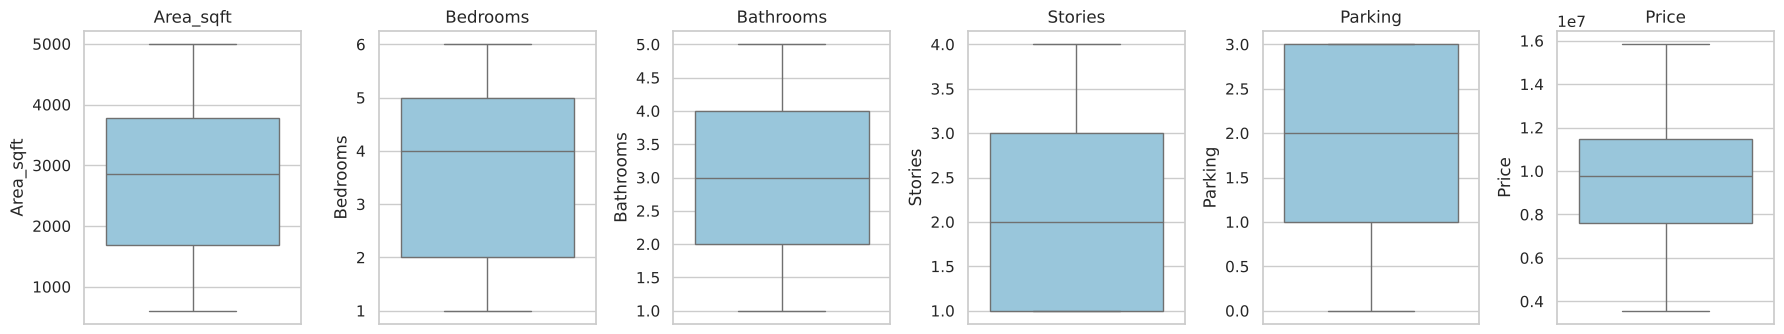

In [6]:
# Outlier check on the target and numeric features using the IQR rule
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

print("IQR outliers per numeric column:")
print(pd.Series({c: iqr_outliers(df[c]) for c in num_cols + [TARGET]}).to_string())

fig, axes = plt.subplots(1, len(num_cols) + 1, figsize=(18, 3.5))
for ax, c in zip(axes, num_cols + [TARGET]):
    sns.boxplot(y=df[c], ax=ax, color="#8ecae6"); ax.set_title(c)
plt.tight_layout(); plt.show()

## 4. Exploratory data analysis

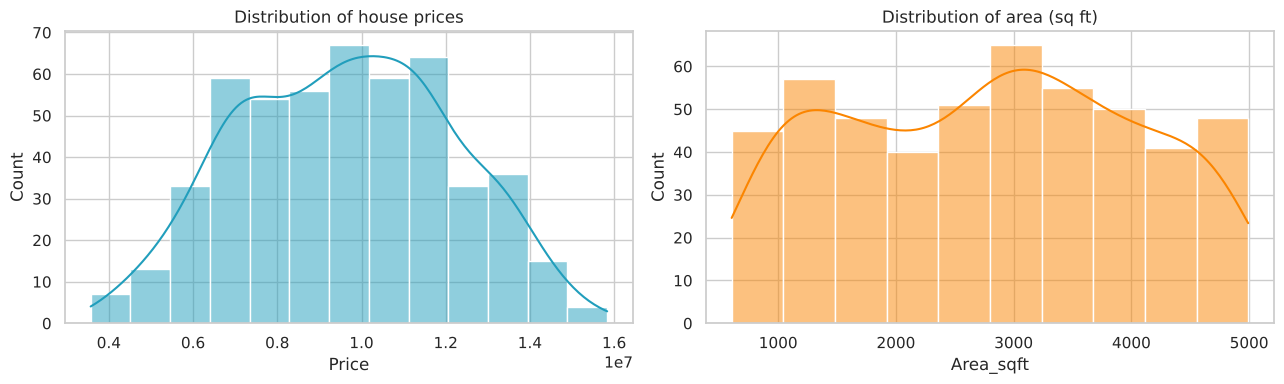

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET], kde=True, ax=axes[0], color="#219ebc")
axes[0].set_title("Distribution of house prices")
sns.histplot(df["Area_sqft"], kde=True, ax=axes[1], color="#fb8500")
axes[1].set_title("Distribution of area (sq ft)")
plt.tight_layout(); plt.show()

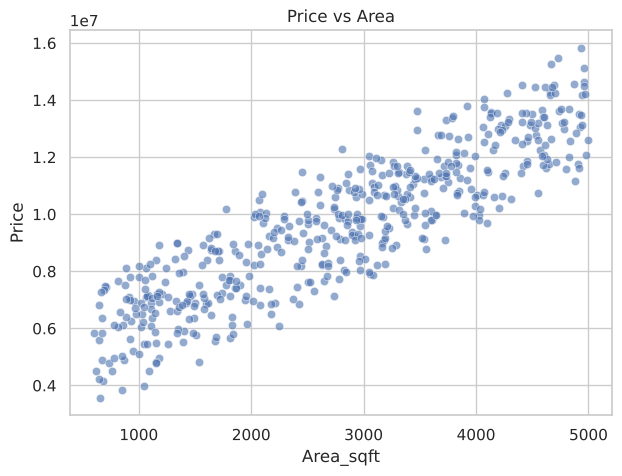

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="Area_sqft", y=TARGET, alpha=0.6, ax=ax)
ax.set_title("Price vs Area"); save_fig("price_vs_area"); plt.show()

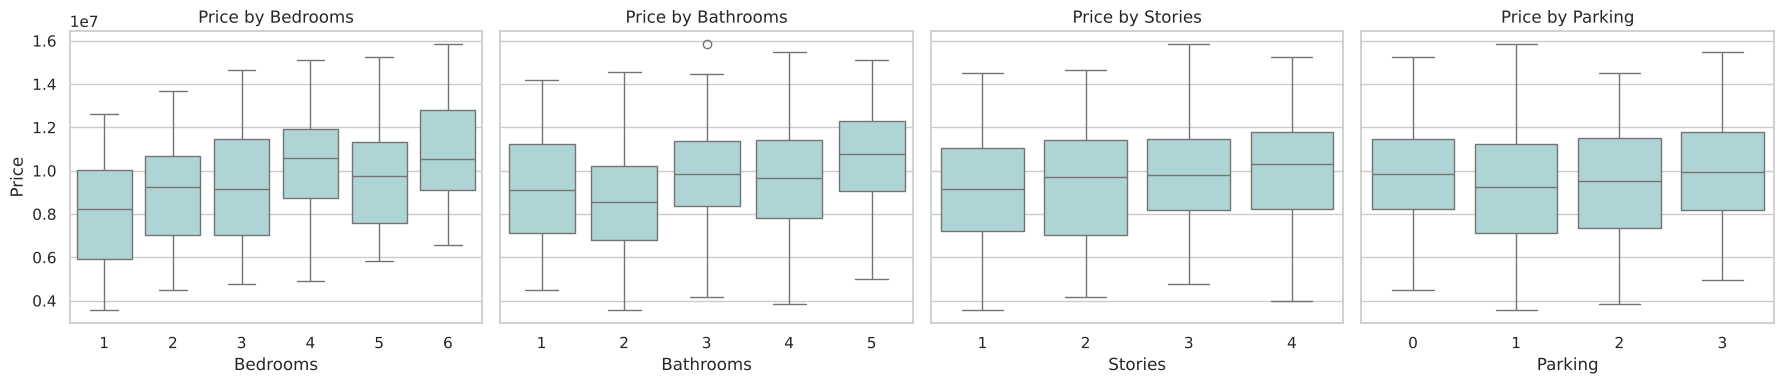

In [9]:
# Price by each discrete feature
disc = ["Bedrooms", "Bathrooms", "Stories", "Parking"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, c in zip(axes, disc):
    sns.boxplot(data=df, x=c, y=TARGET, ax=ax, color="#a8dadc"); ax.set_title(f"Price by {c}")
plt.tight_layout(); plt.show()

Mean price by category:

MainRoad
MainRoad
No    9,369,015
Yes   9,862,506

GuestRoom
GuestRoom
No    9,493,775
Yes   9,754,143

Basement
Basement
No    9,468,078
Yes   9,804,631

HotWaterHeating
HotWaterHeating
No    9,590,201
Yes   9,674,064

AirConditioning
AirConditioning
No    9,494,090
Yes   9,756,913

PreferredArea
PreferredArea
No    9,679,969
Yes   9,573,967

FurnishingStatus
FurnishingStatus
Furnished        9,625,606
Semi-Furnished   9,707,386
Unfurnished      9,559,634


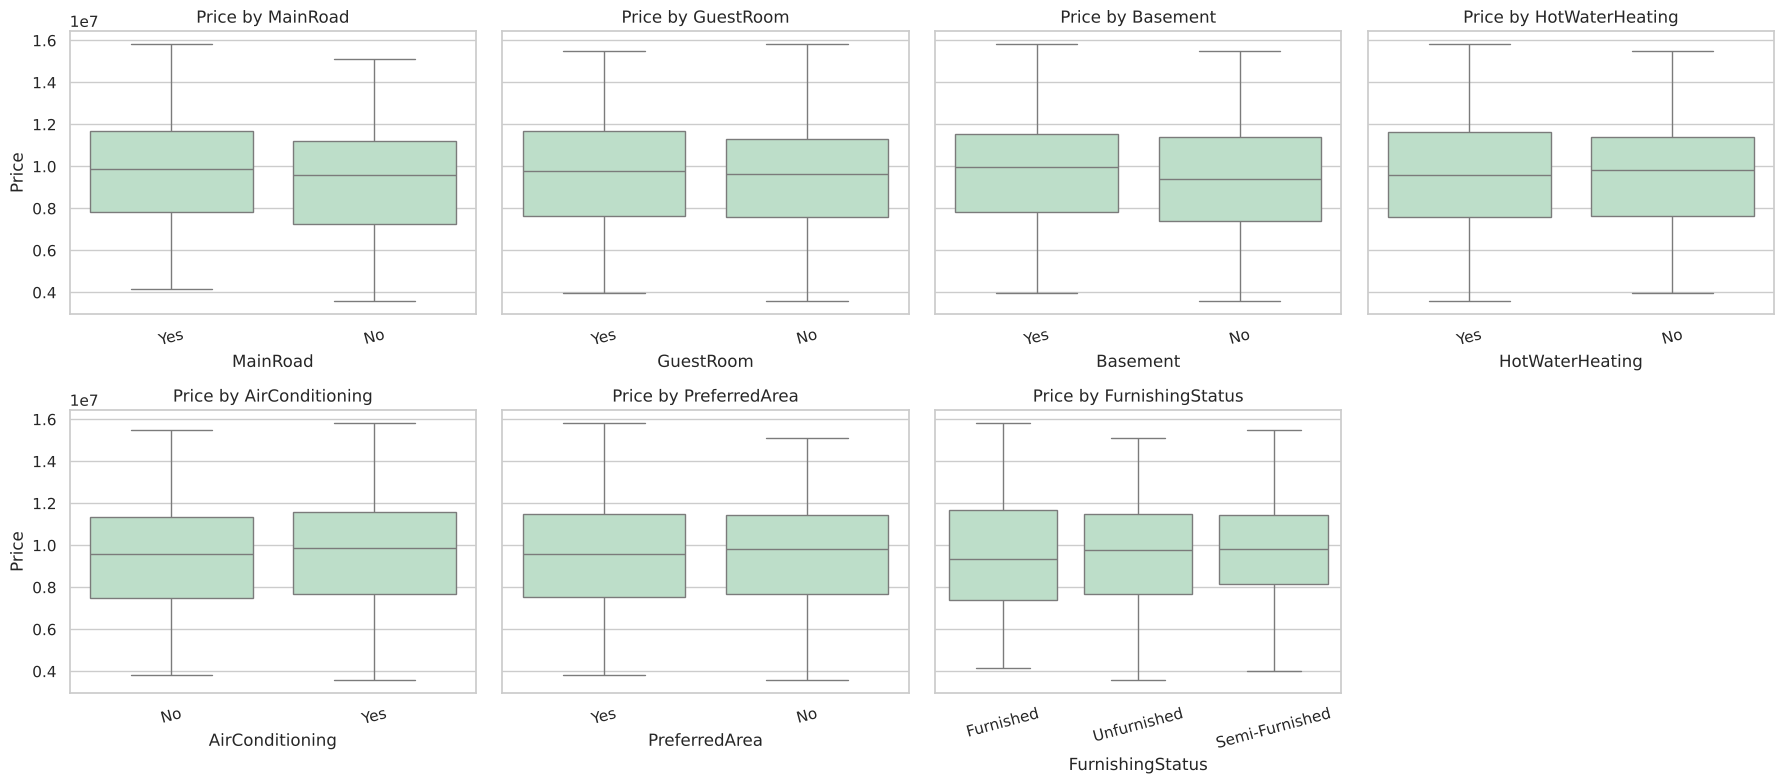

In [10]:
# Price by each categorical feature
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, c in zip(axes.ravel(), cat_cols):
    sns.boxplot(data=df, x=c, y=TARGET, ax=ax, color="#b7e4c7"); ax.set_title(f"Price by {c}")
    ax.tick_params(axis="x", rotation=15)
for ax in axes.ravel()[len(cat_cols):]: ax.axis("off")
plt.tight_layout(); plt.show()

print("Mean price by category:")
for c in cat_cols:
    print(f"\n{c}"); print(df.groupby(c)[TARGET].mean().round(0).to_string())

Correlation with Price:
Area_sqft   0.8883
Bedrooms    0.3168
Bathrooms   0.2327
Stories     0.1278
Parking     0.0618


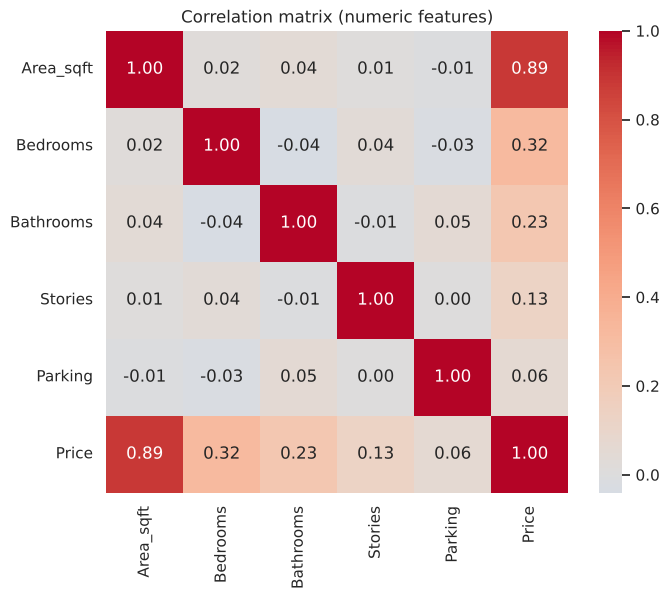

In [11]:
# Correlation of numeric features (annotated heatmap)
corr = df[num_cols + [TARGET]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (numeric features)"); save_fig("correlation_heatmap"); plt.show()

print("Correlation with Price:")
print(corr[TARGET].drop(TARGET).sort_values(ascending=False).to_string())

## 5. Train / test split
The **test set is locked away** now and used only once, at the very end. All model selection is done with cross-validation on the training set — this avoids *data leakage* from picking the winner on test data.

In [12]:
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (400, 12)  Test: (100, 12)


## 6. Preprocessing pipeline
* **Numeric** features → `StandardScaler` (needed by Ridge / linear models; harmless for trees)
* **Yes/No** features → one-hot encoded into a single 0/1 column
* **FurnishingStatus** → one-hot encoded. It has **no natural order**, so it must *not* be label-encoded as 0/1/2 (the original notebook did this, which wrongly imposes an order).

Everything lives inside a `Pipeline`, so scaling/encoding is fitted **only on training folds** and the model accepts **raw data** at prediction time.

In [13]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), binary_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), multi_cols),
    ])

def make_pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge":             Ridge(alpha=1.0),
    "Decision Tree":     DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest":     RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

## 7. Model comparison with 5-fold cross-validation (training data only)

In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

rows = []
for name, mdl in models.items():
    s = cross_validate(make_pipe(mdl), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "Model": name,
        "CV R2 (mean)": s["test_r2"].mean(),
        "CV R2 (std)":  s["test_r2"].std(),
        "CV RMSE": -s["test_rmse"].mean(),
        "CV MAE":  -s["test_mae"].mean(),
    })
cv_results = pd.DataFrame(rows).sort_values("CV R2 (mean)", ascending=False).reset_index(drop=True)
cv_results

,Model,CV R2 (mean),CV R2 (std),CV RMSE,CV MAE
0,Ridge,0.9619,0.0067,"482,492","419,255"
1,Linear Regression,0.9619,0.0067,"482,580","419,114"
2,Gradient Boosting,0.9321,0.0089,"644,938","530,235"
3,Random Forest,0.9099,0.0162,"740,980","610,491"
4,Decision Tree,0.8088,0.0332,"1,078,806","857,502"


Best model by cross-validated R²: Ridge


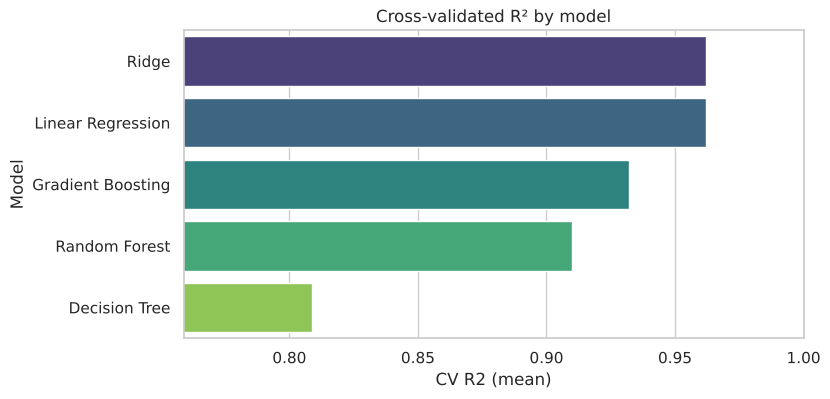

In [15]:
plt.figure(figsize=(8, 4))
sns.barplot(data=cv_results, x="CV R2 (mean)", y="Model", palette="viridis")
plt.xlim(max(0, cv_results["CV R2 (mean)"].min() - 0.05), 1.0)
plt.title("Cross-validated R² by model"); save_fig("model_comparison"); plt.show()

best_name = cv_results.loc[0, "Model"]
print(f"Best model by cross-validated R²: {best_name}")

## 8. Hyper-parameter tuning
The best-scoring model family is tuned with `GridSearchCV` (5-fold CV on the training set). Models with no meaningful hyper-parameters (plain Linear Regression) are used as they are.

In [16]:
param_grids = {
    "Ridge": {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    "Decision Tree": {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 5, 10]},
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [None, 8, 15],
                      "model__min_samples_leaf": [1, 3]},
    "Gradient Boosting": {"model__n_estimators": [100, 300], "model__learning_rate": [0.03, 0.1],
                          "model__max_depth": [2, 3]},
}

if best_name in param_grids:
    search = GridSearchCV(make_pipe(models[best_name]), param_grids[best_name],
                          cv=cv, scoring="r2", n_jobs=-1)
    search.fit(X_train, y_train)
    final_model = search.best_estimator_
    print("Best params :", search.best_params_)
    print(f"Tuned CV R2 : {search.best_score_:.4f}")
else:
    final_model = make_pipe(models[best_name]).fit(X_train, y_train)
    print(f"{best_name} has no hyper-parameters to tune - fitted as is.")

Best params : {'model__alpha': 1}
Tuned CV R2 : 0.9619


## 9. Final evaluation on the held-out test set (used once)

In [17]:
def evaluate(model, Xa, ya):
    p = model.predict(Xa)
    return {"R2": r2_score(ya, p), "MAE": mean_absolute_error(ya, p),
            "RMSE": np.sqrt(mean_squared_error(ya, p))}

train_m = evaluate(final_model, X_train, y_train)
test_m  = evaluate(final_model, X_test,  y_test)
report = pd.DataFrame({"Train": train_m, "Test": test_m}).T
print(f"Final model: {best_name}")
display(report)

gap = train_m["R2"] - test_m["R2"]
print(f"\nTrain R2 - Test R2 gap = {gap:.4f}",
      "-> no sign of serious overfitting" if gap < 0.05 else "-> possible overfitting, review the model")

# Context for the error numbers
print(f"Mean absolute error is {test_m['MAE'] / y_test.mean():.1%} of the average house price.")

# Sanity baseline: a model that always predicts the mean price
baseline_r2 = r2_score(y_test, np.full(len(y_test), y_train.mean()))
print(f"Baseline (always predict the mean) R2 = {baseline_r2:.3f}  vs our model R2 = {test_m['R2']:.3f}")

Final model: Ridge

Train R2 - Test R2 gap = -0.0020 -> no sign of serious overfitting
Mean absolute error is 3.9% of the average house price.
Baseline (always predict the mean) R2 = -0.051  vs our model R2 = 0.967


,R2,MAE,RMSE
Train,0.9653,"404,844","465,116"
Test,0.9674,"397,666","466,296"


In [18]:
# Every candidate evaluated once on the test set (for the report only - NOT used to choose the model)
test_rows = []
for name, mdl in models.items():
    m = make_pipe(mdl).fit(X_train, y_train)
    r = evaluate(m, X_test, y_test); r["Model"] = name; test_rows.append(r)
pd.DataFrame(test_rows).set_index("Model").sort_values("R2", ascending=False)

,R2,MAE,RMSE
Model,,,
Linear Regression,0.9674,"396,577","465,810"
Ridge,0.9674,"397,666","466,296"
Gradient Boosting,0.9451,"506,804","604,701"
Random Forest,0.9204,"586,073","728,043"
Decision Tree,0.8085,"903,229","1,129,474"


## 10. Residual diagnostics

Mean residual: 34,054   (should be close to 0)


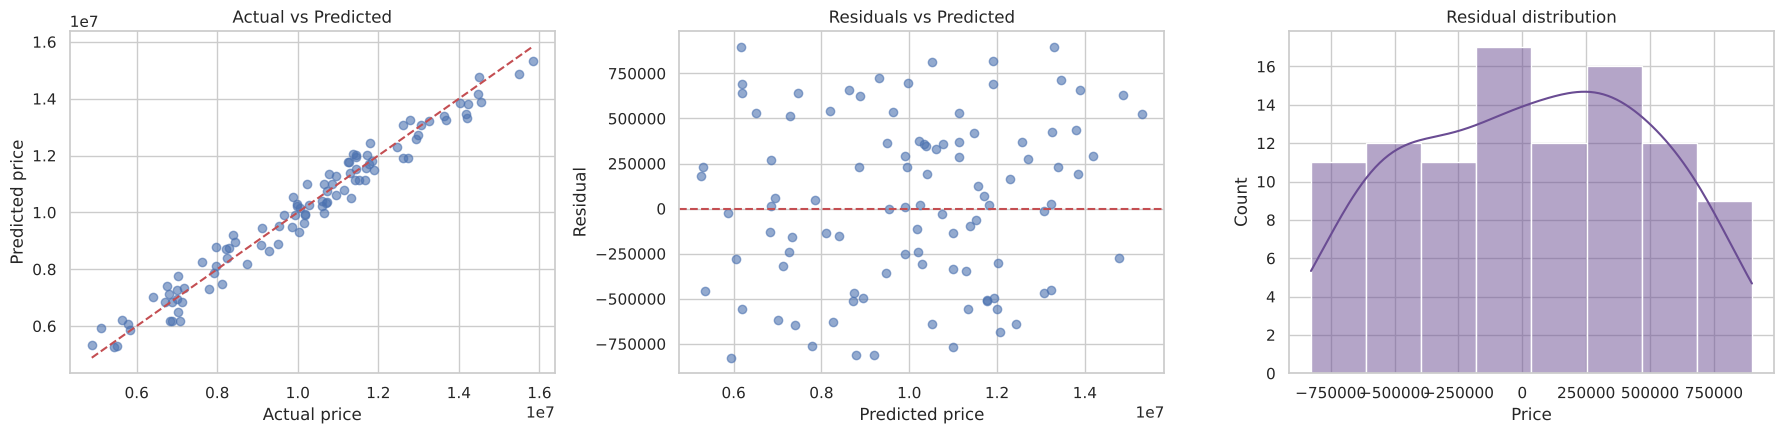

In [19]:
pred = final_model.predict(X_test)
resid = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].scatter(y_test, pred, alpha=0.6)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, "r--"); axes[0].set_xlabel("Actual price"); axes[0].set_ylabel("Predicted price")
axes[0].set_title("Actual vs Predicted")

axes[1].scatter(pred, resid, alpha=0.6); axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_xlabel("Predicted price"); axes[1].set_ylabel("Residual"); axes[1].set_title("Residuals vs Predicted")

sns.histplot(resid, kde=True, ax=axes[2], color="#6a4c93")
axes[2].set_title("Residual distribution")
plt.tight_layout(); save_fig("actual_vs_predicted_residuals"); plt.show()

print(f"Mean residual: {resid.mean():,.0f}   (should be close to 0)")

## 11. Feature importance
We use **permutation importance** on the *original* columns (computed on the test set). Unlike a tree's built-in importance it works for any model and is not biased towards high-cardinality features. Importance = how much R² drops when a feature's values are shuffled.

,Feature,Importance,Std
0,Area_sqft,1.4002,0.1516
1,Bedrooms,0.1780,0.0237
2,Bathrooms,0.0751,0.0092
3,AirConditioning,0.0260,0.0050
4,Stories,0.0240,0.0053
5,Parking,0.0136,0.0027
6,PreferredArea,0.0114,0.0031
7,MainRoad,0.0096,0.0020
8,FurnishingStatus,0.0048,0.0015
9,GuestRoom,0.0021,0.0014


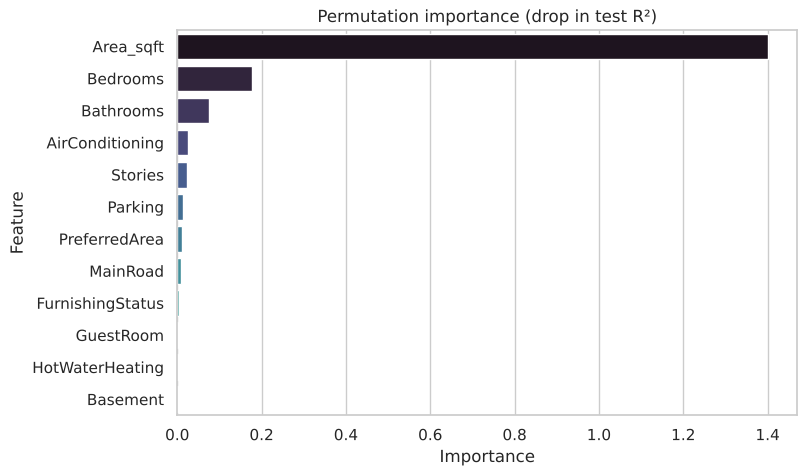

In [20]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=20,
                              random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
imp = pd.DataFrame({"Feature": X.columns, "Importance": perm.importances_mean,
                    "Std": perm.importances_std}).sort_values("Importance", ascending=False)
display(imp.reset_index(drop=True))

plt.figure(figsize=(8, 5))
sns.barplot(data=imp, x="Importance", y="Feature", palette="mako")
plt.title("Permutation importance (drop in test R²)"); save_fig("feature_importance"); plt.show()

## 12. Predict the price of a new house

In [21]:
# Raw values exactly as in the dataset - the pipeline handles all encoding.
new_house = pd.DataFrame([{
    "Area_sqft": 1600, "Bedrooms": 3, "Bathrooms": 2, "Stories": 1,
    "MainRoad": "Yes", "GuestRoom": "No", "Basement": "No",
    "HotWaterHeating": "No", "AirConditioning": "Yes", "Parking": 1,
    "PreferredArea": "Yes", "FurnishingStatus": "Semi-Furnished",
}])[X.columns]

pred_new = final_model.predict(new_house)[0]
mae = test_m["MAE"]
print(f"Predicted price : {pred_new:,.0f}")
print(f"Typical error   : about +/- {mae:,.0f} (test MAE)")

Predicted price : 6,817,032
Typical error   : about +/- 397,666 (test MAE)


In [22]:
# Check we are not extrapolating beyond the training data
print(f"Training area range: {df['Area_sqft'].min()} - {df['Area_sqft'].max()} sq ft")
print("New house inside the training range:",
      df["Area_sqft"].min() <= new_house["Area_sqft"][0] <= df["Area_sqft"].max())

Training area range: 605 - 4992 sq ft
New house inside the training range: True


## 13. Save the trained model

In [23]:
joblib.dump(final_model, MODEL_DIR / "house_price_model.joblib")
reloaded = joblib.load(MODEL_DIR / "house_price_model.joblib")
assert np.allclose(reloaded.predict(new_house), final_model.predict(new_house))
print("Model saved to models/house_price_model.joblib and reload check passed.")
print("Usage: joblib.load('models/house_price_model.joblib').predict(<DataFrame with the 12 raw columns>)")

Model saved to models/house_price_model.joblib and reload check passed.
Usage: joblib.load('models/house_price_model.joblib').predict(<DataFrame with the 12 raw columns>)


## 14. Key insights (generated from the results)

In [24]:
top = imp.head(3)
area_corr = corr.loc["Area_sqft", TARGET]
ppsf = (df[TARGET] / df["Area_sqft"]).median()
cat_effects = {c: df.groupby(c)[TARGET].mean().pipe(lambda s: (s.max() - s.min()) / df[TARGET].mean())
               for c in cat_cols}
weak = [c for c, v in cat_effects.items() if v < 0.05]

print(f"1. Best model: {best_name} (CV R2 = {cv_results.loc[0, 'CV R2 (mean)']:.3f}, test R2 = {test_m['R2']:.3f}).")
print(f"2. Most important features: " + ", ".join(f"{r.Feature} ({r.Importance:.3f})" for r in top.itertuples()) + ".")
print(f"3. Area_sqft correlates {area_corr:.2f} with price; median price per sq ft is about {ppsf:,.0f}.")
print(f"4. Categorical features whose groups differ by <5% in average price: {', '.join(weak) if weak else 'none'}.")
print(f"5. Test error is about {test_m['MAE'] / y_test.mean():.1%} of the average price (MAE {test_m['MAE']:,.0f}).")

1. Best model: Ridge (CV R2 = 0.962, test R2 = 0.967).
2. Most important features: Area_sqft (1.400), Bedrooms (0.178), Bathrooms (0.075).
3. Area_sqft correlates 0.89 with price; median price per sq ft is about 3,414.
4. Categorical features whose groups differ by <5% in average price: GuestRoom, Basement, HotWaterHeating, AirConditioning, PreferredArea, FurnishingStatus.
5. Test error is about 3.9% of the average price (MAE 397,666).


## 15. Limitations (please read)

* **Small dataset** – only 500 rows, so metrics have some uncertainty (see the CV standard deviation above).
* **Data looks synthetic / very clean** – no missing values, no outliers, an almost perfectly linear relationship with area and negligible effects from amenities (guest room, basement, etc.). Real housing markets are noisier, so these scores will **not** transfer to real listings without retraining on real data.
* **Missing real-world drivers** – location/neighbourhood, house age, condition and sale date are not in the data.
* **Currency is not stated** in the dataset, so prices are reported as raw numbers.
* **Extrapolation** – predictions for areas outside the training range (see the check in section 12) are unreliable.

## 16. Conclusion

In [25]:
print(f"Final model : {best_name}")
print(f"Test R2     : {test_m['R2']:.3f}   (baseline mean-predictor: {baseline_r2:.3f})")
print(f"Test MAE    : {test_m['MAE']:,.0f}  ({test_m['MAE'] / y_test.mean():.1%} of average price)")
print(f"Main driver : {imp.iloc[0]['Feature']}")
print()
print("The model explains most of the variation in house prices, driven mainly by the size of the house.")
print("It is built as a leak-free pipeline, selected by cross-validation, evaluated once on unseen data,")
print("and can predict directly from raw house details. Next steps: collect real, larger data with")
print("location information and re-validate before any practical use.")

Final model : Ridge
Test R2     : 0.967   (baseline mean-predictor: -0.051)
Test MAE    : 397,666  (3.9% of average price)
Main driver : Area_sqft

The model explains most of the variation in house prices, driven mainly by the size of the house.
It is built as a leak-free pipeline, selected by cross-validation, evaluated once on unseen data,
and can predict directly from raw house details. Next steps: collect real, larger data with
location information and re-validate before any practical use.
